# RDKit Chemistry Playground
## Visualizing, Exploring, and Breaking Molecules

This notebook is your interactive chemistry sandbox. We will:
1. See how RDKit represents molecules as mathematical graphs.
2. Draw 2D chemical diagrams directly in the notebook.
3. Inspect atoms and bonds programmatically.
4. Experiment with the 3 real-world data problems: invalid SMILES, salts, and canonicalization.
5. Render a gallery of actual molecules from our ESOL dataset.

### Experiment 1: From Text to a 2D Drawing
Let's take **paracetamol** (acetaminophen). In SMILES notation, it is `CC(=O)Nc1ccc(O)cc1`.
Notice: when you evaluate the `mol` variable in the last line of a cell, RDKit draws the SVG structure!

Python type: <class 'rdkit.Chem.rdchem.Mol'>


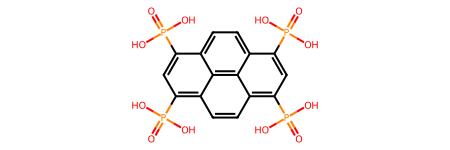

In [ ]:
from rdkit import Chem
from rdkit.Chem import Draw

# Paracetamol (acetaminophen)
smiles_paracetamol = "CC(=O)Nc1ccc(O)cc1"
mol_paracetamol = Chem.MolFromSmiles(smiles_paracetamol)

print("Python object:", type(mol_paracetamol))
mol_paracetamol

### Experiment 2: Inspecting the Molecular Graph
A molecule in RDKit is not a string. It is a **graph** where heavy atoms are nodes and bonds are edges.
Let's count its heavy atoms and list each atom's element, hybridization, and aromaticity.

In [ ]:
print(f"Total heavy atoms: {mol_paracetamol.GetNumHeavyAtoms()}")
print(f"Total bonds: {mol_paracetamol.GetNumBonds()}")
print()
print("--- Heavy Atoms in Paracetamol ---")
for atom in mol_paracetamol.GetAtoms():
    print(
        f"Index {atom.GetIdx():2d} | Element: {atom.GetSymbol():2s} | Aromatic: {atom.GetIsAromatic()} | Explicit H: {atom.GetNumExplicitHs()}"
    )

### Experiment 3: What happens when a SMILES is broken? (Chemical Invalidity)
What does RDKit do if someone gives it a pentavalent carbon `C(C)(C)(C)(C)C` or a ring that never closes `C1CCCC`?
Let's test it!

In [ ]:
# Broken ring (1 opens but never closes)
broken_smiles = "C1CCCCC"
broken_mol = Chem.MolFromSmiles(broken_smiles)

print("Result of broken SMILES:", broken_mol)
if broken_mol is None:
    print(
        "-> RDKit safely returns None instead of crashing! This is how we detect corrupted data."
    )

### Experiment 4: Canonicalization (Different text, same molecule)
Etanol can be written as `CCO`, `OCC`, or even `C(O)C`.
When we convert them into RDKit and back to SMILES using `Chem.MolToSmiles()`, RDKit outputs the exact same standard canonical string.

In [ ]:
variants = ["CCO", "OCC", "C(O)C"]
for s in variants:
    m = Chem.MolFromSmiles(s)
    canonical = Chem.MolToSmiles(m)
    print(f"Input SMILES: {s:8s} -> Canonical SMILES: {canonical}")

### Experiment 5: Salts and Mixtures (The dot notation)
Many drugs are prepared as salts, e.g. **Sodium Benzoate** `[Na+].[O-]C(=O)c1ccccc1`.
The dot `.` means disconnected fragments.
Look at how RDKit draws it, and how we can split it into fragments to keep only the active organic ingredient.

In [ ]:
salt_smiles = "[Na+].[O-]C(=O)c1ccccc1"
salt_mol = Chem.MolFromSmiles(salt_smiles)

# Separate the disconnected pieces
fragments = Chem.GetMolFrags(salt_mol, asMols=True)
print(f"Number of disconnected fragments: {len(fragments)}")
for i, frag in enumerate(fragments):
    print(
        f"  Fragment {i + 1}: {Chem.MolToSmiles(frag)} (Heavy atoms: {frag.GetNumHeavyAtoms()})"
    )

# Draw the salt mixture
salt_mol

### Experiment 6: Drawing a Gallery of ESOL Molecules
Let's load the first 8 molecules from our actual `delaney-processed.csv` dataset and display them in a grid image!

In [ ]:
from pathlib import Path

import pandas as pd

# Robust path lookup whether running from notebooks/ or from project root
data_path = Path("../data/raw/delaney-processed.csv")
if not data_path.exists():
    data_path = Path("data/raw/delaney-processed.csv")

df = pd.read_csv(data_path)
sample_df = df.head(8)

mols = [Chem.MolFromSmiles(s) for s in sample_df["smiles"]]
labels = [
    f"{row['Compound ID']} (LogS: {row['measured log solubility in mols per litre']})"
    for _, row in sample_df.iterrows()
]

Draw.MolsToGridImage(mols, legends=labels, molsPerRow=4, subImgSize=(250, 200))

### Experiment 7: Finding and Highlighting Functional Groups (SMARTS)
A **functional group** is a specific arrangement of atoms responsible for characteristic chemical reactions (e.g., carboxylic acid `-COOH`, alcohol `-OH`, amine `-NH2`).

**SMARTS** is a search query language for chemistry (like regex for text).
Let's ask RDKit to find the carboxylic acid group in **Aspirin** (`CC(=O)Oc1ccccc1C(=O)O`) and highlight those atoms directly on the 2D drawing!

In [ ]:
from rdkit import Chem
from rdkit.Chem import Draw

aspirin = Chem.MolFromSmiles("CC(=O)Oc1ccccc1C(=O)O")

# SMARTS pattern for carboxylic acid: Carbon (sp2) double bonded to Oxygen, single bonded to OH
acid_smarts = Chem.MolFromSmarts("[CX3](=O)[OX2H1]")

# Find matching atom indices in the molecule
matches = aspirin.GetSubstructMatches(acid_smarts)
matched_atom_indices = matches[0] if matches else []

print(f"Found carboxylic acid at atom indices: {matched_atom_indices}")

# Draw with the functional group highlighted in color!
Draw.MolToImage(aspirin, highlightAtoms=matched_atom_indices, size=(300, 250))

### Experiment 8: Calculating Physical Descriptors (The features for ML)
Machine Learning models cannot digest raw molecular drawings directly; they need **numbers**.
RDKit can calculate over 200 physical and chemical descriptors.
Here are the most famous ones used in medicinal chemistry (Lipinski's Rule of 5 for drug-likeness):

- **Molecular Weight (MW):** Mass of the molecule in g/mol.
- **LogP (Octanol/Water Partition Coefficient):** Measures hydrophobicity (lipophilicity). A positive number means the compound prefers oily/organic phases; negative means it prefers water.
- **TPSA (Topological Polar Surface Area):** Surface area occupied by polar atoms (O, N). Crucial for permeability through biological membranes.
- **H-Bond Donors (HBD) & Acceptors (HBA):** Number of hydrogen-bond donors (`-OH`, `-NH`) and acceptors (`=O`, `-N-`).

In [ ]:
from rdkit.Chem import Descriptors

mol = aspirin

mw = Descriptors.MolWt(mol)
logp = Descriptors.MolLogP(mol)
tpsa = Descriptors.TPSA(mol)
hbd = Descriptors.NumHDonors(mol)
hba = Descriptors.NumHAcceptors(mol)
rot_bonds = Descriptors.NumRotatableBonds(mol)

print("=== MOLECULAR DESCRIPTORS FOR ASPIRIN ===")
print(f"Molecular Weight:      {mw:.2f} g/mol")
print(f"LogP (Lipophilicity):   {logp:.2f} (moderate, crosses membranes)")
print(f"Polar Surface (TPSA):  {tpsa:.2f} Å²")
print(f"H-Bond Donors:          {hbd} (-COOH)")
print(f"H-Bond Acceptors:       {hba} (carbonyls & esters)")
print(f"Rotatable Bonds:        {rot_bonds}")

### Experiment 9: Bemis-Murcko Scaffolds (Finding the molecular core)
Medicinal chemists often look at the **core skeleton** (scaffold) of a molecule, stripping away all flexible side chains and decorations.
Why? Because in Machine Learning, if you test a model on molecules with the same scaffold as training, the model cheats.
Let's see what happens when RDKit extracts the Bemis-Murcko scaffold of **Ibuprofen**!

In [ ]:
from rdkit.Chem.Scaffolds import MurckoScaffold

# Ibuprofen: isobutylphenylpropanoic acid
ibuprofen = Chem.MolFromSmiles("CC(C)Cc1ccc(cc1)C(C)C(=O)O")

# Strip all aliphatic side chains down to the ring core
scaffold = MurckoScaffold.GetScaffoldForMol(ibuprofen)

print("Original molecule SMILES: ", Chem.MolToSmiles(ibuprofen))
print("Bemis-Murcko core scaffold:", Chem.MolToSmiles(scaffold))

# Display original vs core scaffold side-by-side
Draw.MolsToGridImage(
    [ibuprofen, scaffold],
    legends=["Original: Ibuprofen", "Core Scaffold: Benzene Ring"],
    molsPerRow=2,
    subImgSize=(300, 200),
)

### Experiment 10: Morgan Fingerprints & Chemical Similarity (Tanimoto)
How does a computer measure how 'similar' two molecules are?

1. **Morgan Fingerprint (ECFP):** Scans circular neighborhoods of radius 2 (ECFP4) and turns the molecule into a 1024-bit binary vector (1 if a subfragment is present, 0 if absent).
2. **Tanimoto Similarity:** Measures the overlap ratio between the two bit vectors:
$$	ext{Tanimoto} = rac{	ext{Common bits}}{	ext{Total unique bits in either}}$$
- `1.0` = identical bit pattern.
- `0.0` = completely unrelated (no shared fragments).
- `>= 0.85` = strongly similar (usually share biological activity).

Let's compare **Ibuprofen**, **Naproxen** (both NSAID pain relievers), and **Caffeine**!

In [ ]:
from rdkit.Chem import DataStructs, rdFingerprintGenerator

# Three molecules
mol_ibuprofen = Chem.MolFromSmiles("CC(C)Cc1ccc(cc1)C(C)C(=O)O")
mol_naproxen = Chem.MolFromSmiles("COc1ccc2cc(ccc2c1)C(C)C(=O)O")  # Similar NSAID
mol_caffeine = Chem.MolFromSmiles(
    "Cn1cnc2c1c(=O)n(c(=O)n2C)C"
)  # Completely different stimulant

# Compute Morgan Fingerprints (radius 2 = ECFP4, 1024 bits)
mfpgen = rdFingerprintGenerator.GetMorganGenerator(radius=2, fpSize=1024)
fp_ibu = mfpgen.GetFingerprint(mol_ibuprofen)
fp_nap = mfpgen.GetFingerprint(mol_naproxen)
fp_caf = mfpgen.GetFingerprint(mol_caffeine)

# Compute Tanimoto similarity
sim_ibu_nap = DataStructs.TanimotoSimilarity(fp_ibu, fp_nap)
sim_ibu_caf = DataStructs.TanimotoSimilarity(fp_ibu, fp_caf)

print("=== CHEMICAL SIMILARITY (TANIMOTO) ===")
print(
    f"Ibuprofen vs Naproxen: {sim_ibu_nap:.3f} (Significant structural overlap: propionic acid on aromatic core)"
)
print(
    f"Ibuprofen vs Caffeine: {sim_ibu_caf:.3f} (Nearly zero similarity: completely different chemistry)"
)

# Draw the three molecules
Draw.MolsToGridImage(
    [mol_ibuprofen, mol_naproxen, mol_caffeine],
    legends=["Ibuprofen", "Naproxen", "Caffeine"],
    molsPerRow=3,
    subImgSize=(250, 200),
)